In [1]:
# Q3 compute the conversion rate per lead_source(closed*lead qualified) and rank sources

In [3]:
import pandas as pd

In [ ]:
import glob
import os

from pathlib import Path

folder = Path("data")
csv_files = glob.glob(os.path.join(folder, "*.csv"))

olist_data = {}

for file in csv_files:
    name = os.path.basename(file).replace(".csv", "")
    olist_data[name] = pd.read_csv(file)

print("Number of CSV files loaded:", len(olist_data))
print("Files loaded:")

for name in olist_data:
    print(name)

Number of CSV files loaded: 12
Files loaded:
customers_202503150948
geolocation_202503150949
geolocation_ascii
leads_closed_202503150950
leads_qualified_202503150950
orders_202503150951
order_items_202503150951
order_payments_202503150951
order_reviews_202503150951
order_reviews_ascii
products_202503150952
sellers_202503150952


In [10]:
reviews = olist_data["order_reviews_202503150951"]
orders = olist_data["orders_202503150951"]

print("Reviews:", reviews.shape)
print("Orders:", orders.shape)

Reviews: (99224, 7)
Orders: (99441, 9)


In [5]:
for name, df in olist_data.items():
    print(name, df.shape)

customers_202503150948 (99441, 5)
geolocation_202503150949 (1000163, 5)
geolocation_ascii (1000163, 5)
leads_closed_202503150950 (842, 14)
leads_qualified_202503150950 (8000, 4)
orders_202503150951 (99441, 8)
order_items_202503150951 (112650, 7)
order_payments_202503150951 (103886, 5)
order_reviews_202503150951 (99224, 7)
order_reviews_ascii (99224, 7)
products_202503150952 (32951, 9)
sellers_202503150952 (3095, 4)


In [6]:
qualified = olist_data["leads_qualified_202503150950"]
closed = olist_data["leads_closed_202503150950"]

print(qualified.columns.tolist())
print(closed.columns.tolist())

['mql_id', 'first_contact_date', 'landing_page_id', 'origin']
['mql_id', 'seller_id', 'sdr_id', 'sr_id', 'won_date', 'business_segment', 'lead_type', 'lead_behaviour_profile', 'has_company', 'has_gtin', 'average_stock', 'business_type', 'declared_product_catalog_size', 'declared_monthly_revenue']


In [6]:
# One row per qualified lead
# Keep leads with a missing source
# Get unique IDs of closed leads
# Mark which qualified leads became closed deals
# Calculate conversion rate by source

In [7]:
qualified_source = (
    qualified[["mql_id", "origin"]]
    .dropna(subset=["mql_id"])
    .drop_duplicates(subset=["mql_id"])
    .copy())

qualified_source["origin"] = qualified_source["origin"].fillna("unknown")

closed_ids = closed["mql_id"].dropna().drop_duplicates()

qualified_source["is_closed"] = qualified_source["mql_id"].isin(closed_ids)

source_results = (
    qualified_source.groupby("origin")
    .agg(
        qualified_leads=("mql_id", "nunique"),
        closed_leads=("is_closed", "sum")))

source_results["conversion_rate"] = (
    source_results["closed_leads"] / source_results["qualified_leads"] * 100).round(2)

display(source_results.sort_values("conversion_rate", ascending=False))

,qualified_leads,closed_leads,conversion_rate
origin,,,
unknown,1159,193,16.65
paid_search,1586,195,12.30
organic_search,2296,271,11.80
direct_traffic,499,56,11.22
referral,284,24,8.45
social,1350,75,5.56
display,118,6,5.08
other_publicities,65,3,4.62
email,493,15,3.04


In [8]:
display( source_results.drop(index="unknown", errors="ignore")
 .sort_values("conversion_rate", ascending=False))

,qualified_leads,closed_leads,conversion_rate
origin,,,
paid_search,1586,195,12.30
organic_search,2296,271,11.80
direct_traffic,499,56,11.22
referral,284,24,8.45
social,1350,75,5.56
display,118,6,5.08
other_publicities,65,3,4.62
email,493,15,3.04
other,150,4,2.67


In [9]:
#Paid search performs best, converting 12.30% of qualified leads.
#Organic search is a close second, at 11.80%, and generates the largest number of closed leads (271).
#Direct traffic also performs well, with an 11.22% conversion rate.
#Email has a low conversion rate of 3.04%, while other has the lowest rate at 2.67%.
#The unknown category had a 16.65% conversion However, its source is unidentified, so it should be reported separately rather than treated as a known marketing channel.
#These results suggest that the business should investigate the effectiveness of paid search, organic search, and direct traffic while reviewing how email and other sources attract and qualify leads.

In [10]:
#Q4 Bucket orders by delivery indays,compute the reviews_score per bucket,
# and say wether the drop off is visible.

In [11]:
orders = olist_data["orders_202503150951"]

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"], errors="coerce")
orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"], errors="coerce")

orders["delivery_days"] = (
    orders["order_delivered_customer_date"]
    - orders["order_purchase_timestamp"]).dt.days

reviews_per_order = (
    reviews.groupby("order_id", as_index=False)["review_score"].mean())

delivery_reviews = orders[["order_id", "delivery_days"]].merge(
    reviews_per_order, on="order_id", how="inner")

delivery_reviews = delivery_reviews[
    delivery_reviews["delivery_days"].notna()
    & (delivery_reviews["delivery_days"] >= 0)].copy()

delivery_reviews["delivery_bucket"] = pd.cut(
    delivery_reviews["delivery_days"],
    bins=[-1, 7, 14, 21, 30, float("inf")],
    labels=["0–7 days", "8–14 days", "15–21 days", "22–30 days", "31+ days"])

bucket_summary = (
    delivery_reviews.groupby("delivery_bucket", observed=False)
    .agg(
        orders=("order_id", "count"),
        average_review_score=("review_score", "mean")).round(2))

display(bucket_summary)

,orders,average_review_score
delivery_bucket,,
0–7 days,33541,4.41
8–14 days,36191,4.29
15–21 days,15264,4.10
22–30 days,6826,3.49
31+ days,4008,2.18


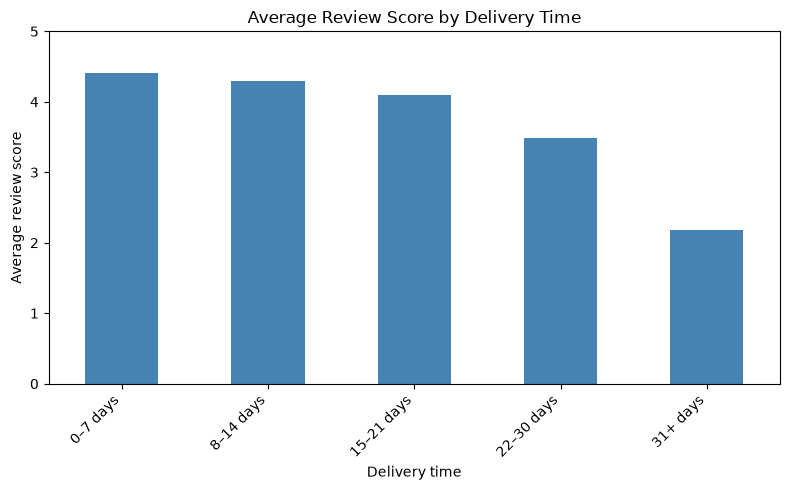

In [12]:
import matplotlib.pyplot as plt

bucket_summary["average_review_score"].plot(
    kind="bar",
    color="steelblue",
    figsize=(8, 5))

plt.title("Average Review Score by Delivery Time")
plt.xlabel("Delivery time")
plt.ylabel("Average review score")
plt.ylim(0, 5)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
##Average review scores declined as delivery time increased, falling from 4.41 for orders delivered
#within 7 days to 2.18 for orders taking 31 days or more. 
#The decline becomes more pronounced after 21 days, 
#suggesting a negative association between longer delivery times and customer satisfaction. 
#This does not prove that delays caused the lower scores. 
#The analysis includes only orders with valid delivery dates and reviews.
#the bussiness should investigate delivery delays and improve logistics to enhance the customer experience.

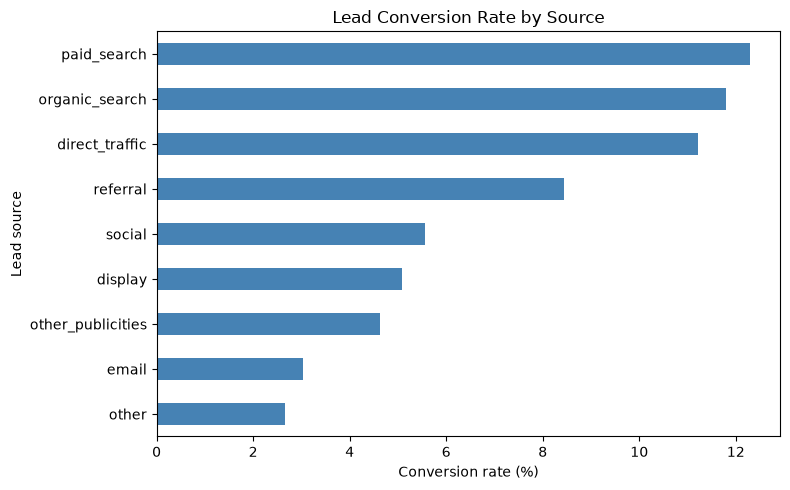

In [13]:
known_sources = source_results.drop(index="unknown", errors="ignore")

known_sources["conversion_rate"].sort_values().plot(
    kind="barh",
    figsize=(8, 5),
    color="steelblue")

plt.title("Lead Conversion Rate by Source")
plt.xlabel("Conversion rate (%)")
plt.ylabel("Lead source")
plt.tight_layout()
plt.show()

In [15]:
reviews = olist_data["order_reviews_202503150951"]
items = olist_data["order_items_202503150951"]
products = olist_data["products_202503150952"]

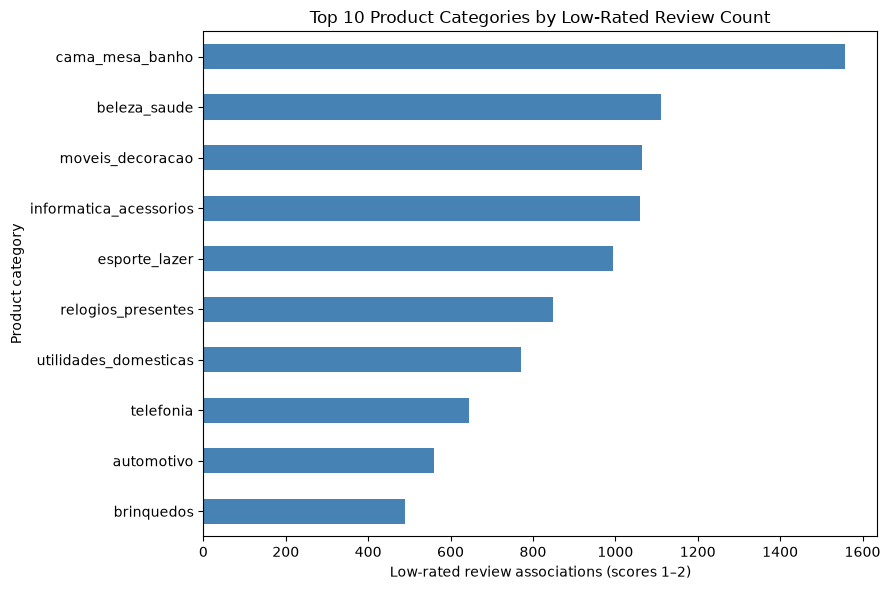

In [16]:
# Link reviews to order items and product categories
category_data = (
    reviews[["review_id", "order_id", "review_score"]]
    .merge(items[["order_id", "product_id"]], on="order_id", how="inner")
    .merge(
        products[["product_id", "product_category_name"]],
        on="product_id",
        how="left")
    .drop_duplicates(subset=["review_id", "product_category_name"]))

#it Keeps rows with a valid score and category
category_data = category_data.dropna(
    subset=["review_score", "product_category_name"]).copy()

category_data["low_rating"] = category_data["review_score"] <= 2

#  this Calculate counts and low-rating rates
category_summary = (
    category_data.groupby("product_category_name")
    .agg(
        total_reviews=("review_score", "count"),
        low_reviews=("low_rating", "sum")))

category_summary["low_review_rate"] = (
    category_summary["low_reviews"] / category_summary["total_reviews"] * 100)

# Plot the 10 categories with the most low-rated review associations
top_by_count = category_summary.nlargest(10, "low_reviews").sort_values("low_reviews")

top_by_count["low_reviews"].plot(
    kind="barh",
    figsize=(9, 6),
    color="steelblue")

plt.title("Top 10 Product Categories by Low-Rated Review Count")
plt.xlabel("Low-rated review associations (scores 1–2)")
plt.ylabel("Product category")
plt.tight_layout()
plt.show()

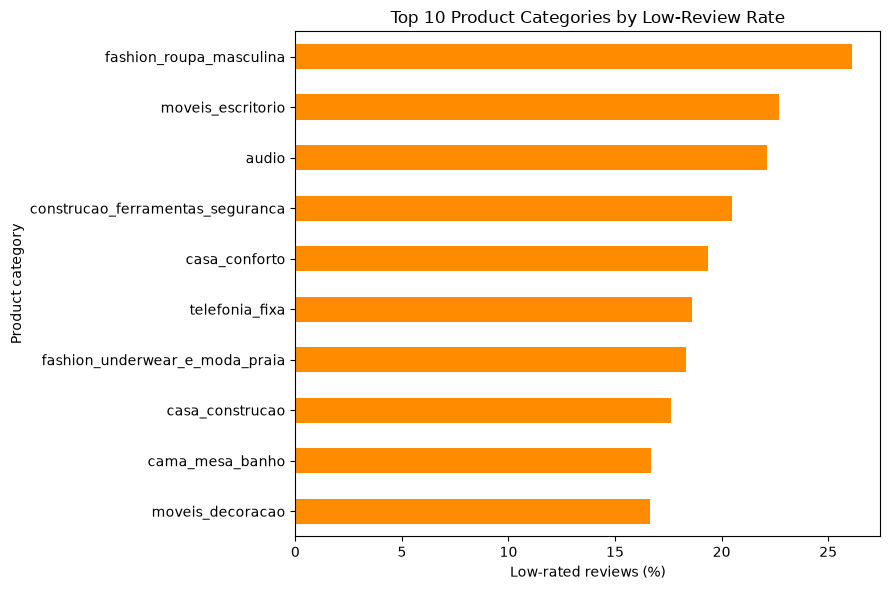

In [17]:
rate_data = category_summary[
    category_summary["total_reviews"] >= 100]

top_by_rate = rate_data.nlargest(10, "low_review_rate").sort_values(
    "low_review_rate")

top_by_rate["low_review_rate"].plot(
    kind="barh",
    figsize=(9, 6),
    color="darkorange")

plt.title("Top 10 Product Categories by Low-Review Rate")
plt.xlabel("Low-rated reviews (%)")
plt.ylabel("Product category")
plt.tight_layout()
plt.show()

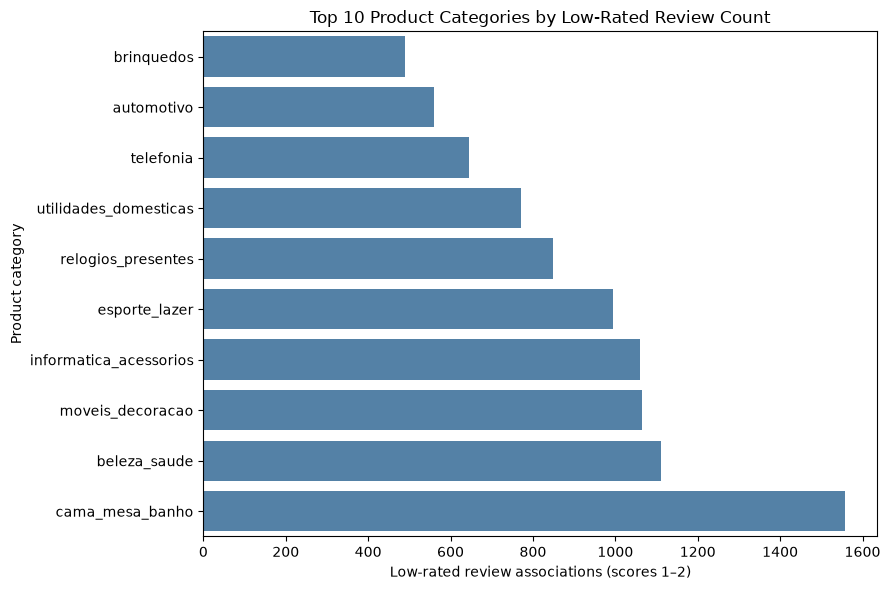

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

plot_data = top_by_count.reset_index()

plt.figure(figsize=(9, 6))
sns.barplot(
    data=plot_data,
    x="low_reviews",
    y="product_category_name",
    color="steelblue")

plt.title("Top 10 Product Categories by Low-Rated Review Count")
plt.xlabel("Low-rated review associations (scores 1–2)")
plt.ylabel("Product category")
plt.tight_layout()
plt.show()

Overall Summary

This analysis examined review scores, low-rated reviews by product category, lead-source conversion, and the relationship between delivery time and review scores.

Review scores: Reviews rated 1 or 2 stars made up 14.69% of scored reviews.
Product categories: cama_mesa_banho had the most low-rated review associations (1,558) and a low-review rate of 16.71%. This is a useful area for further investigation.

Lead conversion: Among identified sources, paid search had the highest conversion rate (12.30%). Organic search generated the most closed leads (271). The unknown source was excluded from the source comparison because it does not identify where leads came from.

Delivery time: Average review scores declined from 4.41 for orders delivered within 0–7 days to 2.18 for orders taking 31 or more days. This pattern shows an association between longer delivery times and lower ratings; it does not prove that delivery time caused the lower scores.